# 01 — Preparação do OCT-C8 e teste do DINOv3
**Projeto:** OCT com poucos dados rotulados. 

## Antes de começar
1. Mantenha o notebook privado durante a configuração. Adicione o dataset [Retinal OCT-C8](https://www.kaggle.com/datasets/obulisainaren/retinal-oct-c8) em **Add Input / Add Data**.
2. Ative Internet para instalar bibliotecas e baixar pesos.
3. Entre no Hugging Face e solicite/aceite o acesso aos dois repositórios abaixo. A permissão pertence à conta: cada integrante deve usar a própria conta autorizada.
4. Crie um token de leitura com permissão para esses repositórios e adicione-o em **Add-ons → Secrets**, com o nome `HF_TOKEN`. Autorize seu uso neste notebook. Não cole o token nas células.

| Modelo do plano | Repositório oficial | Uso nesta etapa |
|---|---|---|
| DINOv3 ViT-L/16, imagens naturais | [facebook/dinov3-vitl16-pretrain-lvd1689m](https://huggingface.co/facebook/dinov3-vitl16-pretrain-lvd1689m) | Verificar acesso e executar |
| RETFound MAE, OCT original | [YukunZhou/RETFound_mae_natureOCT](https://huggingface.co/YukunZhou/RETFound_mae_natureOCT) | Verificar acesso; Ana Júlia configura em outro notebook |

Não trocar pelo DINOv3 de satélites, RETFound CFP ou RETFound-DINOv2. O RETFound original tem implementação própria: não pressupor que `AutoModel` do DINOv3 também o carregue.

**Limite desta etapa:** inventário inicial, não auditoria completa de duplicatas ou pacientes. O teste de retomada será da extração de embeddings, não de treinamento.

## 1 — Instalar o necessário
Execute esta célula antes de importar Transformers. Fixamos `transformers==4.56.2`, uma versão com suporte ao DINOv3. Não reinstalamos PyTorch/CUDA do Kaggle. Se você já importou outra versão de Transformers nesta sessão, reinicie a sessão depois da instalação e comece de novo.

In [1]:
import sys
import subprocess
from importlib.metadata import version

# Identifica bibliotecas que já estavam carregadas antes da instalação.
carregados = [
    nome
    for nome in ["transformers", "huggingface_hub", "tokenizers", "safetensors"]
    if nome in sys.modules
]

# Estes pacotes não são usados neste notebook e conflitam com o Hub fixado.
subprocess.run(
    [sys.executable, "-m", "pip", "uninstall", "-y", "gradio", "diffusers"],
    check=True,
)

# Mantém as versões utilizadas no teste bem-sucedido do projeto.
# Não altera a instalação do PyTorch/CUDA.
subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        "--disable-pip-version-check",
        "transformers==4.56.2",
        "huggingface_hub==0.36.2",
        "safetensors==0.8.0",
    ],
    check=True,
)

print("\nVersões instaladas em disco:")
for pacote in ["transformers", "huggingface_hub", "safetensors"]:
    print(f"{pacote}: {version(pacote)}")

if carregados:
    print(
        "\nATENÇÃO: estas bibliotecas já estavam carregadas:",
        ", ".join(carregados),
    )
    print("Reinicie o kernel antes de executar a próxima célula.")
else:
    print("\nInstalação concluída. Pode executar a próxima célula.")

Found existing installation: gradio 6.26.0
Uninstalling gradio-6.26.0:
  Successfully uninstalled gradio-6.26.0
Found existing installation: diffusers 0.40.0
Uninstalling diffusers-0.40.0:
  Successfully uninstalled diffusers-0.40.0
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.1/40.1 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 93.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 21.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 77.5 MB/s eta 0:00:00
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 1.29.0
    Uninstalling huggingface_hub-1.29.0:
      Successfully uninstalled huggingface_hub-1.29.0
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.23.1
    Uninstalling tokenizers-0.23.1:
      Successfully uninstalled tokenizers-0.23.1
  Attempting uninstall: transformers
    Found existing installation: transformers 5.16.

In [2]:
from importlib.metadata import version
import torch
import transformers
import huggingface_hub
import safetensors

from transformers import AutoImageProcessor, AutoModel

esperadas = {
    "transformers": "4.56.2",
    "huggingface_hub": "0.36.2",
    "safetensors": "0.8.0",
}

modulos = {
    "transformers": transformers,
    "huggingface_hub": huggingface_hub,
    "safetensors": safetensors,
}

problemas = []

for nome, modulo in modulos.items():
    instalada = version(nome)
    carregada = modulo.__version__

    print(f"{nome}: instalada={instalada} | carregada={carregada}")

    if instalada != esperadas[nome]:
        problemas.append(f"{nome}: execute a célula de instalação.")
    elif carregada != instalada:
        problemas.append(f"{nome}: reinicie o kernel.")

if problemas:
    raise RuntimeError("\n".join(problemas))

print("\nPyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("GPU disponível:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Ative a GPU antes de carregar o DINOv3.")

print("\nDependências do projeto verificadas com sucesso.")

transformers: instalada=4.56.2 | carregada=4.56.2
huggingface_hub: instalada=0.36.2 | carregada=0.36.2
safetensors: instalada=0.8.0 | carregada=0.8.0

PyTorch: 2.11.0+cu128
CUDA: 12.8
GPU disponível: True
GPU: Tesla T4

Dependências do projeto verificadas com sucesso.


## 2 — Configuração e padrão de arquivos
- `/kaggle/input`: entradas anexadas; tratar como somente leitura.
- `/kaggle/working/oct_project`: arquivos do projeto gerados nesta sessão.
- `/kaggle/temp/oct_hf_cache`: cache descartável dos pesos; não faz parte do backup.
- Nomes: minúsculas, sem espaços/acentos; manter classe, divisão, modelo, fração e semente quando aplicáveis.
- Futuro exemplo: `octc8_dinov3_vitl16_linear_p01_seed17`.

Este notebook usa `octc8_inventory_v1.csv` e `dinov3_vitl16_smoke_<assinatura>/chunk_00000.npz`. A assinatura impede misturar extrações de configurações diferentes.

In [3]:
from pathlib import Path
import os, json, hashlib, random, time, platform, shutil, importlib.metadata
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display, FileLink

PROJECT = Path("/kaggle/working/oct_project")
CACHE = Path("/kaggle/temp/oct_hf_cache")
for sub in ["metadata", "manifests", "figures", "smoke"]:
    (PROJECT / sub).mkdir(parents=True, exist_ok=True)
CACHE.mkdir(parents=True, exist_ok=True)
os.environ["HF_HOME"] = str(CACHE)

SEED = 17
DATA_ROOT_OVERRIDE = ""  # Se a descoberta falhar, copie aqui o caminho exibido na seção 4.
DINO_REVISION = None     # Primeira execução: resolve o commit atual e o registra.
# Para repetir em outra sessão, use o commit salvo em metadata/model_access.json.
PREVIOUS_SMOKE_DIR = ""  # Opcional: pasta de extração anexada de uma sessão anterior.
CLASSES = ["AMD", "CNV", "CSR", "DME", "DR", "DRUSEN", "MH", "NORMAL"]
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASSES)}
DINO_ID = "facebook/dinov3-vitl16-pretrain-lvd1689m"
RETFOUND_ID = "YukunZhou/RETFound_mae_natureOCT"

random.seed(SEED)
np.random.seed(SEED)
def save_json(path, obj):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding="utf-8")
    tmp.replace(path)

save_json(PROJECT / "metadata/class_to_idx.json", CLASS_TO_IDX)
print("Saídas:", PROJECT)
print("Classes:", CLASS_TO_IDX)

Saídas: /kaggle/working/oct_project
Classes: {'AMD': 0, 'CNV': 1, 'CSR': 2, 'DME': 3, 'DR': 4, 'DRUSEN': 5, 'MH': 6, 'NORMAL': 7}


## 3 — Registrar o ambiente
O registro inclui as bibliotecas instaladas, sem exportar tokens ou variáveis de ambiente. Se a GPU estiver desligada agora, atualize esta célula depois de ativá-la. Se houver duas GPUs, este teste usa apenas `cuda:0`.

In [4]:
import torch
import transformers
assert transformers.__version__ == "4.56.2", "Reinicie a sessão após instalar a versão fixada."
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

def write_environment():
    names = ["torch", "torchvision", "transformers", "huggingface_hub", "safetensors",
             "numpy", "pandas", "Pillow", "matplotlib"]
    versions = {}
    for name in names:
        try:
            versions[name] = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            versions[name] = "não instalado"
    env = {"python": platform.python_version(), "libraries": versions,
           "cuda_available": torch.cuda.is_available(), "torch_cuda": torch.version.cuda,
           "gpus": [{"name": torch.cuda.get_device_name(i),
                     "memory_gib": round(torch.cuda.get_device_properties(i).total_memory / 2**30, 2)}
                    for i in range(torch.cuda.device_count())]}
    save_json(PROJECT / "metadata/environment.json", env)
    # Versões, sem pip freeze com URLs de repositórios ou credenciais.
    installed = sorted({(d.metadata.get("Name") or "unknown") + "==" + d.version
                        for d in importlib.metadata.distributions()})
    (PROJECT / "metadata/installed_versions.txt").write_text("\n".join(installed))
    return env

display(write_environment())

{'python': '3.13.15',
 'libraries': {'torch': '2.11.0+cu128',
  'torchvision': '0.26.0+cu128',
  'transformers': '4.56.2',
  'huggingface_hub': '0.36.2',
  'safetensors': '0.8.0',
  'numpy': '2.1.3',
  'pandas': '2.3.3',
  'Pillow': '12.3.0',
  'matplotlib': '3.10.0'},
 'cuda_available': True,
 'torch_cuda': '12.8',
 'gpus': [{'name': 'Tesla T4', 'memory_gib': 14.56},
  {'name': 'Tesla T4', 'memory_gib': 14.56}]}

## 4 — Localizar o OCT-C8
A célula não pressupõe uma estrutura interna específica. Ela procura a pasta do dataset e mostra as primeiras pastas. Se não encontrar ou houver mais de uma cópia, ajuste `DATA_ROOT_OVERRIDE` na seção 2.

Se aparecer somente um ZIP, será preciso descompactá-lo antes e apontar para a pasta extraída; a célula não considera um ZIP como imagens já disponíveis.

In [5]:
INPUT = Path("/kaggle/input")
assert INPUT.exists(), "Este notebook foi preparado para o Kaggle."
print("Entradas anexadas:")
for item in sorted(INPUT.iterdir()):
    print(" -", item)

if DATA_ROOT_OVERRIDE:
    DATA_ROOT = Path(DATA_ROOT_OVERRIDE)
else:
    candidates = sorted({p for p in INPUT.rglob("*")
                         if p.is_dir() and p.name.lower() == "retinal-oct-c8"})
    if len(candidates) != 1:
        raise RuntimeError("Não encontrei uma única pasta retinal-oct-c8. Confira as entradas e preencha DATA_ROOT_OVERRIDE.")
    DATA_ROOT = candidates[0]
assert DATA_ROOT.is_dir(), f"Pasta inexistente: {DATA_ROOT}"
print("\nRaiz escolhida:", DATA_ROOT)
dirs = sorted(p for p in DATA_ROOT.rglob("*") if p.is_dir())
for p in dirs[:45]:
    print("  ", p.relative_to(DATA_ROOT))
if len(dirs) > 45:
    print(f"... outras {len(dirs)-45} pastas")

Entradas anexadas:
 - /kaggle/input/datasets

Raiz escolhida: /kaggle/input/datasets/obulisainaren/retinal-oct-c8
   RetinalOCT_Dataset
   RetinalOCT_Dataset/RetinalOCT_Dataset
   RetinalOCT_Dataset/RetinalOCT_Dataset/test
   RetinalOCT_Dataset/RetinalOCT_Dataset/test/AMD
   RetinalOCT_Dataset/RetinalOCT_Dataset/test/CNV
   RetinalOCT_Dataset/RetinalOCT_Dataset/test/CSR
   RetinalOCT_Dataset/RetinalOCT_Dataset/test/DME
   RetinalOCT_Dataset/RetinalOCT_Dataset/test/DR
   RetinalOCT_Dataset/RetinalOCT_Dataset/test/DRUSEN
   RetinalOCT_Dataset/RetinalOCT_Dataset/test/MH
   RetinalOCT_Dataset/RetinalOCT_Dataset/test/NORMAL
   RetinalOCT_Dataset/RetinalOCT_Dataset/train
   RetinalOCT_Dataset/RetinalOCT_Dataset/train/AMD
   RetinalOCT_Dataset/RetinalOCT_Dataset/train/CNV
   RetinalOCT_Dataset/RetinalOCT_Dataset/train/CSR
   RetinalOCT_Dataset/RetinalOCT_Dataset/train/DME
   RetinalOCT_Dataset/RetinalOCT_Dataset/train/DR
   RetinalOCT_Dataset/RetinalOCT_Dataset/train/DRUSEN
   RetinalOCT_Data

## 5 — Conferir divisões e classes
A célula reconhece `train`, `val`/`validation`/`valid` e `test` (também `training`/`testing`). As classes são identificadas pelo nome da pasta. Se algum nome for diferente, ela para para que você confira; não tenta adivinhar.

O `image_id` é calculado a partir do caminho relativo, não do conteúdo. Portanto, **este inventário não detecta imagens duplicadas**. Dimensões, hashes de conteúdo e identificação de pacientes serão acrescentados na auditoria seguinte.

In [6]:
SPLIT_ALIASES = {"train": "train", "training": "train", "val": "val",
                 "valid": "val", "validation": "val", "test": "test", "testing": "test"}
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def classify_path(path, root):
    rel = path.relative_to(root)
    parts = rel.parts[:-1]
    splits = {SPLIT_ALIASES[x.lower()] for x in parts if x.lower() in SPLIT_ALIASES}
    labels = {x.upper() for x in parts if x.upper() in CLASS_TO_IDX}
    if len(splits) != 1 or len(labels) != 1:
        return None
    label = next(iter(labels))
    return {"image_id": hashlib.sha256(rel.as_posix().encode()).hexdigest()[:20],
            "relative_path": rel.as_posix(), "split": next(iter(splits)),
            "class_name": label, "class_id": CLASS_TO_IDX[label]}

files = sorted(p for p in DATA_ROOT.rglob("*") if p.is_file() and p.suffix.lower() in EXTENSIONS)
assert files, "Nenhuma imagem encontrada. Confira a raiz ou se o dataset está compactado."
rows, unrecognized = [], []
for path in files:
    row = classify_path(path, DATA_ROOT)
    if row is None:
        unrecognized.append(str(path.relative_to(DATA_ROOT)))
    else:
        rows.append(row)
if unrecognized:
    print("Caminhos que precisam de conferência:", unrecognized[:20])
    raise RuntimeError("Ajuste os nomes de pastas/classes antes de continuar; nenhuma imagem será ignorada silenciosamente.")
manifest = pd.DataFrame(rows).sort_values(["split", "class_name", "relative_path"]).reset_index(drop=True)
assert manifest.image_id.is_unique
assert set(manifest.split) == {"train", "val", "test"}, "Falta uma divisão: conferir estrutura."
counts = pd.crosstab(manifest.class_name, manifest.split).reindex(index=CLASSES, columns=["train", "val", "test"], fill_value=0).fillna(0).astype(int)
assert (counts > 0).all().all(), "Há classe ausente em alguma divisão; conferir dados."
manifest.to_csv(PROJECT / "manifests/octc8_inventory_v1.csv", index=False)
counts.to_csv(PROJECT / "manifests/octc8_counts_v1.csv")
display(counts)
print("Totais:", manifest.groupby("split").size().to_dict())
print("Total geral:", len(manifest))
expected = {"train": 2300, "val": 350, "test": 350}
matches = all((counts[s] == n).all() for s, n in expected.items())
print("Contagens coincidem com a proposta:", matches)
if not matches:
    print("ATENÇÃO: registrar e investigar a diferença. Não apagar imagens para forçar as contagens.")
save_json(PROJECT / "metadata/data_inventory_status.json", {
    "data_root": str(DATA_ROOT), "total": len(manifest),
    "matches_proposal_counts": bool(matches), "full_image_audit_done": False})

split,train,val,test
class_name,,,
AMD,2300,350,350
CNV,2300,350,350
CSR,2300,350,350
DME,2300,350,350
DR,2300,350,350
DRUSEN,2300,350,350
MH,2300,350,350
NORMAL,2300,350,350


Totais: {'test': 2800, 'train': 18400, 'val': 2800}
Total geral: 24000
Contagens coincidem com a proposta: True


## 6 — Mostrar imagens de treino
Escolher até duas imagens de treino por classe, com semente fixa. Conferir se abrem, seus tamanhos e modos de cor. A figura mostra uma por classe e o teste do modelo usa a mesma pequena amostra. Não usamos imagens de teste para tomar decisões.

,image_id,width,height,mode
0,9f612e696b9754ea7a03,1000,512,RGB
1,660872559fc11749e317,1000,512,RGB
2,5ed89053187dcd300791,512,496,L
3,2b02b31548ffc4a4c906,1536,496,L
4,0ad93d6c20f0655abf5d,750,500,RGB
5,9625e547486463b71163,750,500,RGB
6,a2bfd110f8a54f3b3c88,512,496,L
7,9a244ab4efeed3f73d05,512,496,L
8,1c8a6060680f08d2f577,750,500,RGB
9,9b266743a51c932d3a6e,750,500,RGB


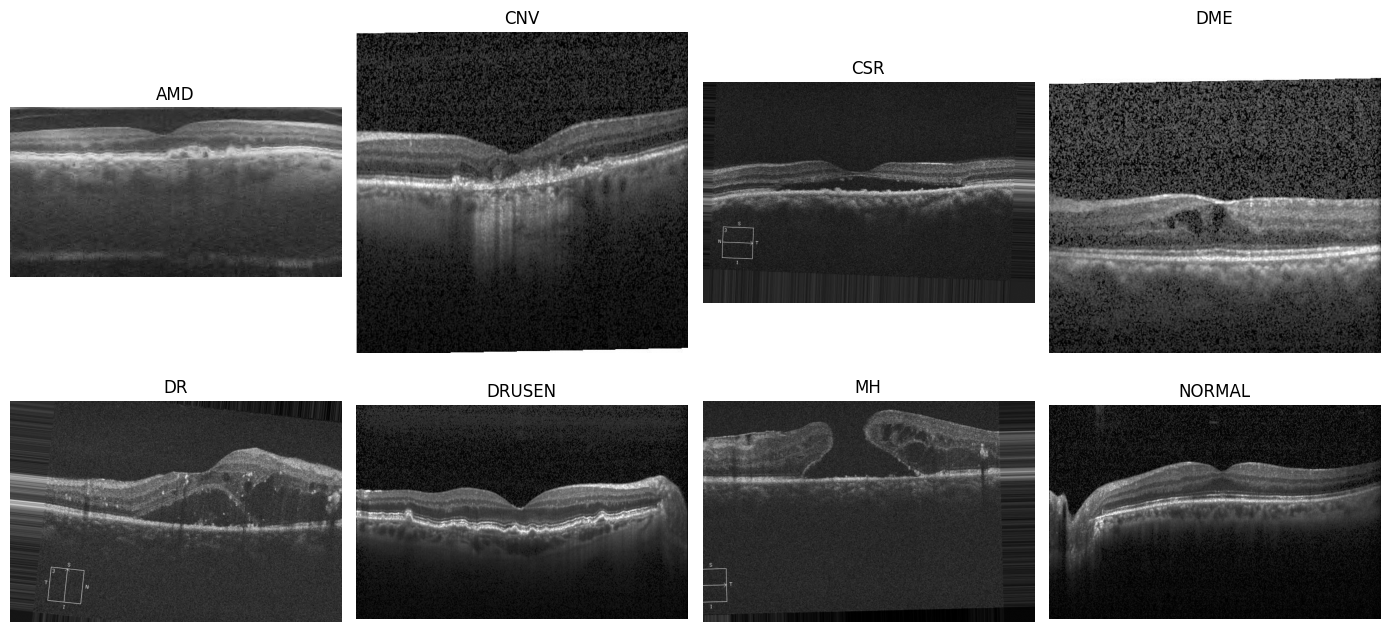

In [7]:
rng = random.Random(SEED)
sample_rows = []
for name in CLASSES:
    candidates = manifest[(manifest.split == "train") & (manifest.class_name == name)]
    indices = rng.sample(list(candidates.index), min(2, len(candidates)))
    sample_rows.extend(manifest.loc[indices].to_dict("records"))
sample = pd.DataFrame(sample_rows).reset_index(drop=True)
checks = []
for row in sample.to_dict("records"):
    with Image.open(DATA_ROOT / row["relative_path"]) as im:
        im.load()  # Falha aqui se uma das imagens selecionadas não puder ser lida.
        checks.append({"image_id": row["image_id"], "width": im.width,
                       "height": im.height, "mode": im.mode})
display(pd.DataFrame(checks))
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, name in zip(axes.ravel(), CLASSES):
    row = sample[sample.class_name == name].iloc[0]
    with Image.open(DATA_ROOT / row.relative_path) as im:
        ax.imshow(im.convert("L"), cmap="gray")
    ax.set_title(name)
    ax.axis("off")
fig.tight_layout()
fig.savefig(PROJECT / "figures/octc8_train_examples.png", dpi=140, bbox_inches="tight")
plt.show()
sample.to_csv(PROJECT / "manifests/smoke_sample_seed17.csv", index=False)

## 7 — Verificar o acesso aos pesos sem baixar tudo
Esta célula usa seu token apenas em memória. Consulta o commit e testa acesso ao cabeçalho de um arquivo de pesos. Ver a página pública de um modelo não significa ter acesso aos pesos.

Se RETFound estiver bloqueado, registre a pendência para Ana Júlia; isso não impede o teste do DINOv3. Não compartilhem tokens.

In [9]:
from huggingface_hub import HfApi, hf_hub_url, get_hf_file_metadata
from kaggle_secrets import UserSecretsClient
try:
    hf_token = UserSecretsClient().get_secret("HF_TOKEN")
except Exception:
    raise RuntimeError("Cadastre HF_TOKEN em Add-ons → Secrets e autorize seu uso no notebook.") from None

api = HfApi(token=hf_token)
access = {}
for repo_id, requested_revision in [(DINO_ID, DINO_REVISION), (RETFOUND_ID, None)]:
    try:
        info = api.model_info(repo_id, revision=requested_revision)
        weight_files = sorted(x.rfilename for x in info.siblings
                              if x.rfilename.endswith((".safetensors", ".pth", ".pt", ".bin")))
        if not weight_files:
            raise RuntimeError("Nenhum arquivo de pesos reconhecido.")
        probe = get_hf_file_metadata(hf_hub_url(repo_id, weight_files[0], revision=info.sha), token=hf_token)
        access[repo_id] = {"accessible": True, "revision": info.sha,
                           "probed_weight_file": weight_files[0], "size_bytes": probe.size}
        print(repo_id, "→ acesso aos pesos confirmado; commit", info.sha)
    except Exception as exc:
        status = getattr(getattr(exc, "response", None), "status_code", None)
        access[repo_id] = {"accessible": False, "error_type": type(exc).__name__, "http_status": status}
        print(repo_id, "→ acesso não confirmado:", type(exc).__name__, "HTTP", status)
        # Não imprimir a exceção completa: manter logs sem tokens/URLs de download assinadas.
save_json(PROJECT / "metadata/model_access.json", access)
print("Se houver 401/403: conferir conta autorizada, aprovação, token e permissões. Se houver falha de rede: conferir Internet.")

facebook/dinov3-vitl16-pretrain-lvd1689m → acesso aos pesos confirmado; commit ea8dc2863c51be0a264bab82070e3e8836b02d51
YukunZhou/RETFound_mae_natureOCT → acesso não confirmado: GatedRepoError HTTP 403
Se houver 401/403: conferir conta autorizada, aprovação, token e permissões. Se houver falha de rede: conferir Internet.


## 8 — Carregar o DINOv3 na GPU
Ative uma GPU nas configurações do notebook antes desta célula. O piloto usa batch 2 e apenas uma GPU. O carregamento pode levar alguns minutos, dependendo da conexão.

Usamos o commit registrado, extração do token global CLS e entrada de 224 × 224. Para este piloto, redimensionamos a imagem inteira para 224 × 224 sem corte central, com normalização indicada pelo processador oficial. Essa decisão deve ser revisada e fixada no protocolo antes dos experimentos principais.

In [10]:
from transformers import AutoImageProcessor, AutoModel
assert torch.cuda.is_available(), "Ative a GPU nas configurações. Se a sessão reiniciar, execute as células anteriores."
assert access.get(DINO_ID, {}).get("accessible"), "O acesso ao DINOv3 ainda não foi confirmado."
REVISION = access[DINO_ID]["revision"]
DEVICE = torch.device("cuda:0")
# Evita manter duas cópias ao reexecutar esta célula.
if "model" in globals():
    del model
    torch.cuda.empty_cache()
processor = AutoImageProcessor.from_pretrained(DINO_ID, revision=REVISION,
                                              token=hf_token, cache_dir=str(CACHE), use_fast=True)
model = AutoModel.from_pretrained(DINO_ID, revision=REVISION, token=hf_token,
                                 cache_dir=str(CACHE), dtype=torch.float32)
model.eval().requires_grad_(False)
model.to(DEVICE)
assert model.config.hidden_size == 1024, "Conferir se foi carregado o ViT-L/16 esperado."
write_environment()
print("Modelo:", DINO_ID)
print("Commit:", REVISION)
print("Parâmetros:", f"{sum(p.numel() for p in model.parameters()):,}")
print("Dimensão do vetor:", model.config.hidden_size)
print("GPU:", torch.cuda.get_device_name(0))

preprocessor_config.json:   0%|          | 0.00/585 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/745 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.21G [00:00<?, ?B/s]

Modelo: facebook/dinov3-vitl16-pretrain-lvd1689m
Commit: ea8dc2863c51be0a264bab82070e3e8836b02d51
Parâmetros: 303,129,600
Dimensão do vetor: 1024
GPU: Tesla T4


## 9 — Preparar o teste retomável
A extração será salva em pequenos blocos. Um bloco só recebe o nome definitivo depois de ser gravado. Na retomada, o código confere configuração, imagens e formato antes de reutilizar os blocos.

Para testar **entre sessões**, anexe a saída anterior ao novo notebook e preencha `PREVIOUS_SMOKE_DIR` na seção 2 com a pasta `dinov3_vitl16_smoke_...`. Use também o mesmo commit em `DINO_REVISION`. O código abaixo copia somente arquivos dessa pasta e confere a assinatura. Se mudar imagens, pesos ou processamento, inicia-se outra extração.

In [11]:
def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

BATCH_SIZE = 2
AMP_DTYPE = torch.float16
spec = {"model_id": DINO_ID, "revision": REVISION, "size": [224, 224],
        "resize": "PIL_BICUBIC_whole_image", "processor": processor.to_dict(),
        "feature": "last_hidden_state_cls_token", "dimension": model.config.hidden_size,
        "amp_dtype": "float16", "batch_size": BATCH_SIZE,
        "transformers": transformers.__version__, "torch": str(torch.__version__),
        "seed": SEED,
        "images": [{"image_id": r["image_id"], "relative_path": r["relative_path"],
                    "sha256": file_sha256(DATA_ROOT / r["relative_path"])}
                   for r in sample.to_dict("records")]}
canonical = json.dumps(spec, sort_keys=True, ensure_ascii=False)
signature = hashlib.sha256(canonical.encode()).hexdigest()[:16]
RUN = PROJECT / "smoke" / f"dinov3_vitl16_smoke_{signature}"
RUN.mkdir(exist_ok=True)

if PREVIOUS_SMOKE_DIR:
    previous = Path(PREVIOUS_SMOKE_DIR)
    assert previous.is_dir(), "A pasta anterior não foi encontrada."
    old_spec = json.loads((previous / "run_spec.json").read_text())
    assert old_spec == spec, "A configuração anterior difere: não reutilizar esses blocos."
    for src in previous.glob("chunk_*.npz"):
        dst = RUN / src.name
        if not dst.exists():
            shutil.copy2(src, dst)
if (RUN / "run_spec.json").exists():
    assert json.loads((RUN / "run_spec.json").read_text()) == spec
save_json(RUN / "run_spec.json", spec)
print("Pasta da execução:", RUN)

@torch.inference_mode()
def embed_rows(rows):
    images = []
    for row in rows:
        with Image.open(DATA_ROOT / row["relative_path"]) as im:
            images.append(im.convert("RGB").resize((224, 224), Image.Resampling.BICUBIC))
    inputs = processor(images=images, return_tensors="pt", do_resize=False, do_center_crop=False)
    assert tuple(inputs["pixel_values"].shape[-2:]) == (224, 224)
    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
    with torch.autocast(device_type="cuda", dtype=AMP_DTYPE):
        outputs = model(**inputs)
        embeddings = outputs.last_hidden_state[:, 0, :].float().cpu().numpy()
    assert embeddings.shape == (len(rows), model.config.hidden_size)
    assert np.isfinite(embeddings).all()
    return embeddings

def check_chunk(path, rows):
    with np.load(path, allow_pickle=False) as z:
        assert z["signature"].item() == signature, "Bloco de outra configuração."
        assert z["image_ids"].tolist() == [r["image_id"] for r in rows]
        assert z["class_ids"].tolist() == [r["class_id"] for r in rows]
        assert z["embeddings"].shape == (len(rows), model.config.hidden_size)
        assert np.isfinite(z["embeddings"]).all()

def run_extraction(max_new_batches=None):
    records = sample.to_dict("records")
    saved, reused = 0, 0
    started = time.perf_counter()
    torch.cuda.reset_peak_memory_stats()
    for start in range(0, len(records), BATCH_SIZE):
        rows = records[start:start + BATCH_SIZE]
        path = RUN / f"chunk_{start // BATCH_SIZE:05d}.npz"
        if path.exists():
            check_chunk(path, rows)
            reused += 1
            continue
        if max_new_batches is not None and saved >= max_new_batches:
            break
        vectors = embed_rows(rows)
        tmp = path.with_suffix(".tmp")
        with open(tmp, "wb") as f:
            np.savez_compressed(f, embeddings=vectors,
                                image_ids=np.array([r["image_id"] for r in rows]),
                                class_ids=np.array([r["class_id"] for r in rows]),
                                signature=np.array(signature))
        tmp.replace(path)
        check_chunk(path, rows)
        saved += 1
        save_json(RUN / "progress.json", {"signature": signature,
                   "completed_chunks": len(list(RUN.glob("chunk_*.npz"))),
                   "total_chunks": (len(records) + BATCH_SIZE - 1) // BATCH_SIZE})
    torch.cuda.synchronize()
    result = {"new_chunks": saved, "reused_chunks": reused,
              "seconds": round(time.perf_counter() - started, 3),
              "peak_memory_gib": round(torch.cuda.max_memory_allocated() / 2**30, 3)}
    print(result)
    return result

Pasta da execução: /kaggle/working/oct_project/smoke/dinov3_vitl16_smoke_7bf94818bb82f73c


## 10 — Interromper de forma controlada e continuar
Na primeira chamada, salvar apenas dois blocos novos. Na segunda, continuar e reaproveitar o que já está salvo. Na terceira, conferir que nada foi recalculado.

Isso testa a retomada na sessão atual. Para comprovar a retomada após perder a sessão, siga a seção 12 e repita em uma sessão nova. Não significa que arquivos temporários serão preservados automaticamente.

In [12]:
first_pass = run_extraction(max_new_batches=2)
resume_pass = run_extraction()
verification_pass = run_extraction()
assert verification_pass["new_chunks"] == 0
expected_chunks = (len(sample) + BATCH_SIZE - 1) // BATCH_SIZE
assert verification_pass["reused_chunks"] == expected_chunks
blocks, ids = [], []
for path in sorted(RUN.glob("chunk_*.npz")):
    with np.load(path, allow_pickle=False) as z:
        blocks.append(z["embeddings"])
        ids.extend(z["image_ids"].tolist())
embeddings = np.concatenate(blocks)
assert ids == sample.image_id.tolist()
assert embeddings.shape == (len(sample), 1024)
save_json(RUN / "smoke_test_report.json", {
    "completed": True, "shape": list(embeddings.shape),
    "same_session_resume_verified": True,
    "restored_previous_directory": bool(PREVIOUS_SMOKE_DIR),
    "first_pass": first_pass, "resume_pass": resume_pass,
    "verification_pass": verification_pass})
print("SUCESSO: imagens processadas e blocos reutilizados sem recalcular.")
print("Formato final:", embeddings.shape)
print("Isto é um teste de infraestrutura, não uma avaliação de classificação.")

{'new_chunks': 2, 'reused_chunks': 0, 'seconds': 1.534, 'peak_memory_gib': 1.157}
{'new_chunks': 6, 'reused_chunks': 2, 'seconds': 0.365, 'peak_memory_gib': 1.157}
{'new_chunks': 0, 'reused_chunks': 8, 'seconds': 0.009, 'peak_memory_gib': 1.139}
SUCESSO: imagens processadas e blocos reutilizados sem recalcular.
Formato final: (16, 1024)
Isto é um teste de infraestrutura, não uma avaliação de classificação.


## 11 — Fazer um backup dos resultados pequenos
O ZIP contém manifesto, contagens, figura, registros e os blocos do teste. Não contém token, imagens originais nem pesos do modelo.

Se o acesso ao DINOv3 estiver pendente, você pode executar esta célula após a seção 7 para guardar a preparação dos dados. Isso não significa que o teste do modelo foi concluído.

In [13]:
archive = shutil.make_archive("/kaggle/working/oct_setup_backup", "zip", root_dir=PROJECT)
print("Backup:", archive)
print("Tamanho em MB:", round(Path(archive).stat().st_size / 1e6, 2))
display(FileLink(archive))
print("Baixe o ZIP ou confirme os arquivos na saída de uma versão salva antes de encerrar a sessão.")

Backup: /kaggle/working/oct_setup_backup.zip
Tamanho em MB: 1.76


/kaggle/working/oct_setup_backup.zip

Baixe o ZIP ou confirme os arquivos na saída de uma versão salva antes de encerrar a sessão.


In [14]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import display, FileLink

PROJECT = Path("/kaggle/working/oct_project")

# Usa a execução atual, se a variável RUN ainda estiver disponível.
run_dir = globals().get("RUN")

if run_dir is None:
    candidates = sorted(
        (PROJECT / "smoke").glob("dinov3_vitl16_smoke_*")
    )
    if len(candidates) != 1:
        raise RuntimeError(
            "Não foi possível identificar uma única execução. "
            "Defina run_dir com o caminho da execução desejada."
        )
    run_dir = candidates[0]

run_dir = Path(run_dir)

# Origem no Kaggle → destino dentro do ZIP.
files = {
    PROJECT / "manifests/octc8_inventory_v1.csv":
        "data/manifests/octc8_inventory_v1.csv",

    PROJECT / "manifests/octc8_counts_v1.csv":
        "reports/data_audit/octc8_counts_v1.csv",

    PROJECT / "metadata/environment.json":
        "environment/environment.json",

    PROJECT / "metadata/installed_versions.txt":
        "environment/installed_versions.txt",

    PROJECT / "metadata/class_to_idx.json":
        "data/manifests/class_to_idx.json",

    PROJECT / "metadata/data_inventory_status.json":
        "reports/data_audit/data_inventory_status.json",

    PROJECT / "metadata/model_access.json":
        "reports/smoke_tests/dinov3/model_access.json",

    run_dir / "run_spec.json":
        "reports/smoke_tests/dinov3/run_spec.json",

    run_dir / "smoke_test_report.json":
        "reports/smoke_tests/dinov3/smoke_test_report.json",
}

missing = [str(source) for source in files if not source.is_file()]
if missing:
    raise FileNotFoundError(
        "Arquivos não encontrados:\n" + "\n".join(missing)
    )

zip_path = Path("/kaggle/working/oct_repo_files.zip")

with ZipFile(zip_path, "w", compression=ZIP_DEFLATED) as archive:
    for source, destination in files.items():
        archive.write(source, arcname=destination)

print(f"ZIP criado com {len(files)} arquivos.")
display(FileLink(str(zip_path)))

ZIP criado com 9 arquivos.


/kaggle/working/oct_repo_files.zip

In [15]:
from pathlib import Path
from IPython.display import HTML, display
import base64

arquivo = Path("/kaggle/working/oct_setup_backup.zip")

if not arquivo.is_file():
    print(
        "O ZIP não está nesta sessão. "
        "Se a pasta oct_project ainda existir, execute novamente "
        "a célula que cria o backup."
    )
else:
    conteudo = base64.b64encode(arquivo.read_bytes()).decode("ascii")
    display(HTML(
        f'<a download="{arquivo.name}" '
        f'href="data:application/zip;base64,{conteudo}">'
        f'Baixar {arquivo.name}</a>'
    ))

In [16]:
arquivo = Path("/kaggle/working/oct_repo_files.zip")

## 12 — Salvar no Kaggle e testar em uma sessão nova
1. Use **Save Version**, escolhendo uma opção que preserve os arquivos de saída. Em **Save & Run All**, aguarde terminar e confira a opção de salvar saídas quando exibida. A execução poderá baixar os pesos e rodar novamente; reserve tempo/cota.
2. Abra a versão salva e confira **Output**. Verifique `oct_setup_backup.zip`, `oct_project/metadata` e `oct_project/smoke`. Não confunda salvar apenas o código com preservar arquivos.
3. Baixe o ZIP como cópia adicional. Guardar em `/kaggle/working` durante uma sessão não garante que os arquivos estarão lá na próxima.
4. Na próxima sessão, adicione a saída salva como entrada do notebook, ou anexe uma cópia privada dos seus arquivos. Encontre a pasta que contém `run_spec.json` e `chunk_*.npz`.
5. Preencha `PREVIOUS_SMOKE_DIR` com essa pasta e `DINO_REVISION` com o commit salvo. Use o mesmo dataset, versões e configuração. Execute novamente: todos os blocos existentes devem ser reutilizados. Se você tiver apenas o ZIP anexado, extraia seus próprios arquivos antes e aponte para a pasta de extração.
6. O cache dos pesos é temporário e poderá precisar de novo download. Não publicar os pesos restritos como parte dos resultados.

## Critério para concluir a etapa
- [ ] Checkpoints corretos identificados e situação de acesso registrada.
- [ ] Inventário e contagens salvos; eventuais diferenças registradas.
- [ ] Exemplos de treino exibidos sem erro.
- [ ] DINOv3 carrega e produz vetores de 1.024 números.
- [ ] Retomada na mesma sessão funciona sem recalcular blocos.
- [ ] Backup baixado ou saídas confirmadas na versão salva.
- [ ] Retomada entre sessões verificada separadamente.

**Ainda faltará na auditoria seguinte:** abrir todas as imagens, procurar duplicatas por conteúdo e semelhança, investigar pacientes e origem, e fixar as divisões antes dos experimentos.

## Se ocorrer erro
| Situação | Próximo passo |
|---|---|
| Dataset não encontrado | Conferir Add Input e definir `DATA_ROOT_OVERRIDE` com o caminho real |
| Classe/divisão não reconhecida | Mostrar os caminhos impressos e ajustar o mapeamento após conferir |
| `401` ou `403` | Conferir acesso aprovado na mesma conta do token, escopo do token e autorização do Secret |
| Falha de rede | Conferir Internet; não interpretar automaticamente como falta de permissão |
| Sem GPU | Ativar acelerador; repetir a configuração caso a sessão reinicie |
| Falta de memória | Reiniciar para liberar modelos antigos; tentar batch 1, que gera outra assinatura |
| Configuração diferente na retomada | Conferir commit, versões, imagens e transformações; não misturar arquivos |
| Erro de importação após instalar | Reiniciar a sessão e executar desde a primeira célula; não reinstalar CUDA aleatoriamente |

## Referências consultadas em 18/10/2026
- Meta: https://github.com/facebookresearch/dinov3
- Checkpoint DINOv3: https://huggingface.co/facebook/dinov3-vitl16-pretrain-lvd1689m
- Transformers DINOv3: https://huggingface.co/docs/transformers/model_doc/dinov3
- RETFound oficial: https://github.com/rmaphoh/RETFound
- RETFound OCT: https://huggingface.co/YukunZhou/RETFound_mae_natureOCT
- OCT-C8: https://www.kaggle.com/datasets/obulisainaren/retinal-oct-c8
- Kaggle Secrets: https://www.kaggle.com/discussions/product-feedback/114053

**Validação do arquivo:** estrutura e sintaxe verificadas localmente; células de inventário e retomada testadas com dados sintéticos. O acesso real ao dataset, aos pesos e à GPU precisa ser verificado na sua sessão Kaggle. Nenhum resultado de modelo foi preenchido antecipadamente.